# Section 6 — Recommendation & Memo: สรุปแผนปฏิบัติการ 18 เดือน
**Business Question:** แล้วสรุป Shopee ควรทำอะไร และจัดลำดับความสำคัญอย่างไร?

### ข้อเสนอแนะ 3 เสาหลัก (3 Strategic Pillars)
1. **Priority 1 (เดือนที่ 0–12): ป้องกันฐาน Intent-based + ยกระดับ SPX Express** — ล็อกกลุ่มลูกค้าที่ตั้งใจซื้อ (Search & Shopee Mall) ด้วยการการันตีความเร็วจัดส่งและคุณภาพสินค้าที่ TikTok Shop ทำตามได้ยาก
2. **Priority 2 (เดือนที่ 2–14): เปลี่ยนกฎรัฐเป็น Moat (ปั้น OTOP 4% + Local SME)** — ดึงผู้ผลิตไทยและสินค้า OTOP เข้าแพลตฟอร์มด้วยเรต GP 4% สร้างความได้เปรียบด้านราคาเหนือสินค้า Cross-border ที่โดน VAT 7%
3. **Priority 3 (เดือนที่ 4–18): รุก Affiliate & Live แบบเจาะจงหมวด Margin สูง** — ใช้งบอุดหนุนเฉพาะหมวด Beauty, Fashion และ Personal Care ที่มีกำไรสูง เพื่อหยุดการรั่วไหลของลูกค้าโดยไม่ทำลายบรรทัดสุดท้าย (Bottom-line)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chart_style

chart_style.setup_plot_style()
COLORS = chart_style.COLORS

rec_df = pd.read_csv("../data/processed/sec06_roadmap_and_impact.csv")
display(rec_df)

,rec_id,rec_title,start_month,duration_months,end_month,priority_level,expected_impact_index,key_kpi
0,Rec 1,1. ป้องกันฐาน Intent-based + ยกระดับ SPX Express,0,12,12,Priority 1: Core Defense,92,Retention ของกลุ่ม Mall/Search & เวลาจัดส่งเฉลี่ย
1,Rec 2,2. เปลี่ยนกฎรัฐเป็น Moat (ปั้น OTOP 4% + Local...,2,12,14,Priority 2: Structural Moat,84,จำนวนร้าน OTOP/SME ใหม่ & สัดส่วน Local GMV
2,Rec 3,3. รุก Affiliate & Live แบบเจาะจงหมวด Margin สูง,4,14,18,Priority 3: Selective Attack,71,ROI ของงบอุดหนุน Live & Take-rate สุทธิ


### กราฟ 6.1 — Priority Roadmap (Gantt Timeline 0–18 Months)
- **สื่ออะไร:** ลำดับการลงมือทำอย่างเป็นระบบใน 18 เดือน เริ่มจากการล็อกฐานกำไรเดิมทันทีในเดือนแรก ตามด้วยการขยายฐานร้านค้าไทยรับกฎหมายใหม่ และการทำ Selective Attack ในฝั่ง Creator Affiliate

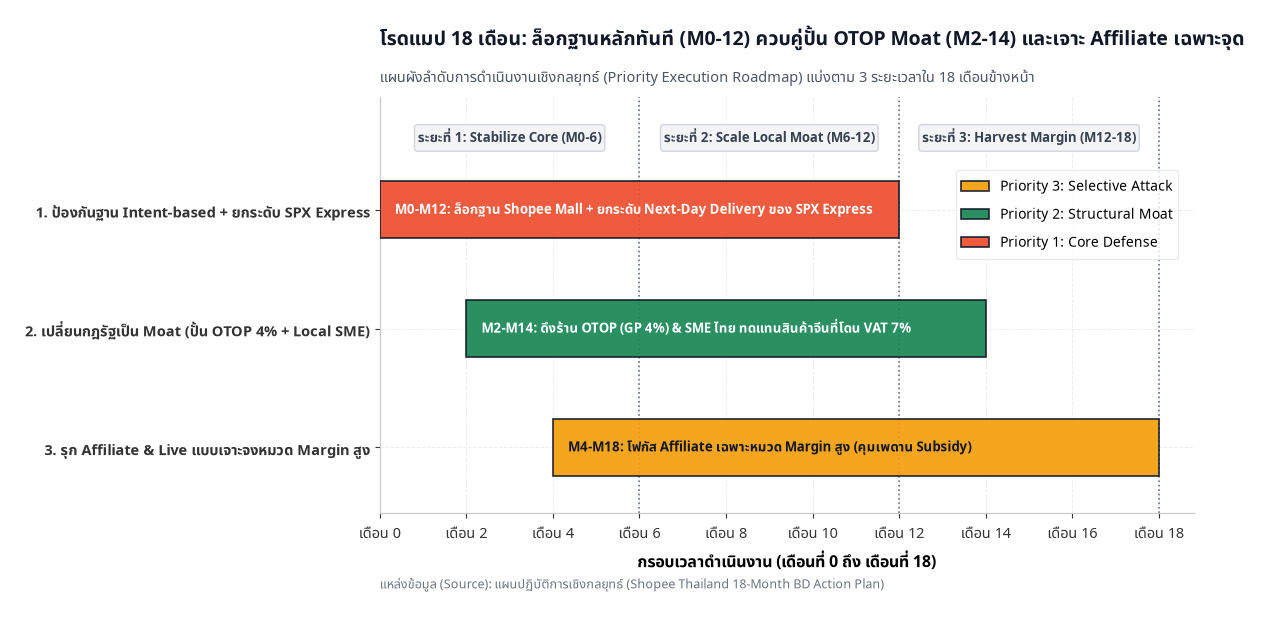

In [2]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))

df_plot = rec_df.iloc[::-1].reset_index(drop=True)
y_pos = np.arange(len(df_plot))

bar_colors = ["#F59E0B", COLORS["OTOP"], COLORS["Shopee"]]
milestones = [
    "M4-M18: โฟกัส Affiliate เฉพาะหมวด Margin สูง (คุมเพดาน Subsidy)",
    "M2-M14: ดึงร้าน OTOP (GP 4%) & SME ไทย ทดแทนสินค้าจีนที่โดน VAT 7%",
    "M0-M12: ล็อกฐาน Shopee Mall + ยกระดับ Next-Day Delivery ของ SPX Express"
]

for i, row in df_plot.iterrows():
    ax.barh(
        i, row["duration_months"], left=row["start_month"], height=0.48,
        color=bar_colors[i], edgecolor="#111827", linewidth=1.2, alpha=0.92,
        label=row["priority_level"], zorder=3
    )
    ax.text(
        row["start_month"] + 0.35, i, milestones[i],
        ha="left", va="center", fontsize=9.5, fontweight="bold",
        color="#FFFFFF" if i != 0 else "#111827", zorder=4
    )

for m, p_label in [(6, "ระยะที่ 1: Stabilize Core (M0-6)"), (12, "ระยะที่ 2: Scale Local Moat (M6-12)"), (18, "ระยะที่ 3: Harvest Margin (M12-18)")]:
    ax.axvline(m, color="#6B7280", linestyle=":", linewidth=1.2, zorder=2)
    ax.text(m - 3, 2.52, p_label, ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#374151",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="#F3F4F6", edgecolor="#D1D5DB"))

ax.set_yticks(y_pos)
ax.set_yticklabels(df_plot["rec_title"], fontsize=10.5, fontweight="bold")
ax.set_xlabel("กรอบเวลาดำเนินงาน (เดือนที่ 0 ถึง เดือนที่ 18)", fontweight="bold")
ax.set_xticks(range(0, 19, 2))
ax.set_xticklabels([f"เดือน {m}" for m in range(0, 19, 2)])
ax.set_xlim(0, 18.8)
ax.set_ylim(-0.55, 2.95)
ax.legend(loc="upper right", bbox_to_anchor=(0.99, 0.84))

chart_style.add_title_and_source(
    ax,
    title="โรดแมป 18 เดือน: ล็อกฐานหลักทันที (M0-12) ควบคู่ปั้น OTOP Moat (M2-14) และเจาะ Affiliate เฉพาะจุด",
    subtitle="แผนผังลำดับการดำเนินงานเชิงกลยุทธ์ (Priority Execution Roadmap) แบ่งตาม 3 ระยะเวลาใน 18 เดือนข้างหน้า",
    source_text="แผนปฏิบัติการเชิงกลยุทธ์ (Shopee Thailand 18-Month BD Action Plan)"
)

plt.savefig("../charts/06_1_priority_roadmap.png")
plt.show()

### กราฟ 6.2 — Expected Impact Summary
- **สื่ออะไร:** สรุปเปรียบเทียบผลกระทบคาดหวัง (Expected Impact Index) ของทั้ง 3 ข้อเสนอแนะให้เห็นชัดเจนใน 3 วินาที พร้อม KPI หลักที่ใช้ติดตามผล

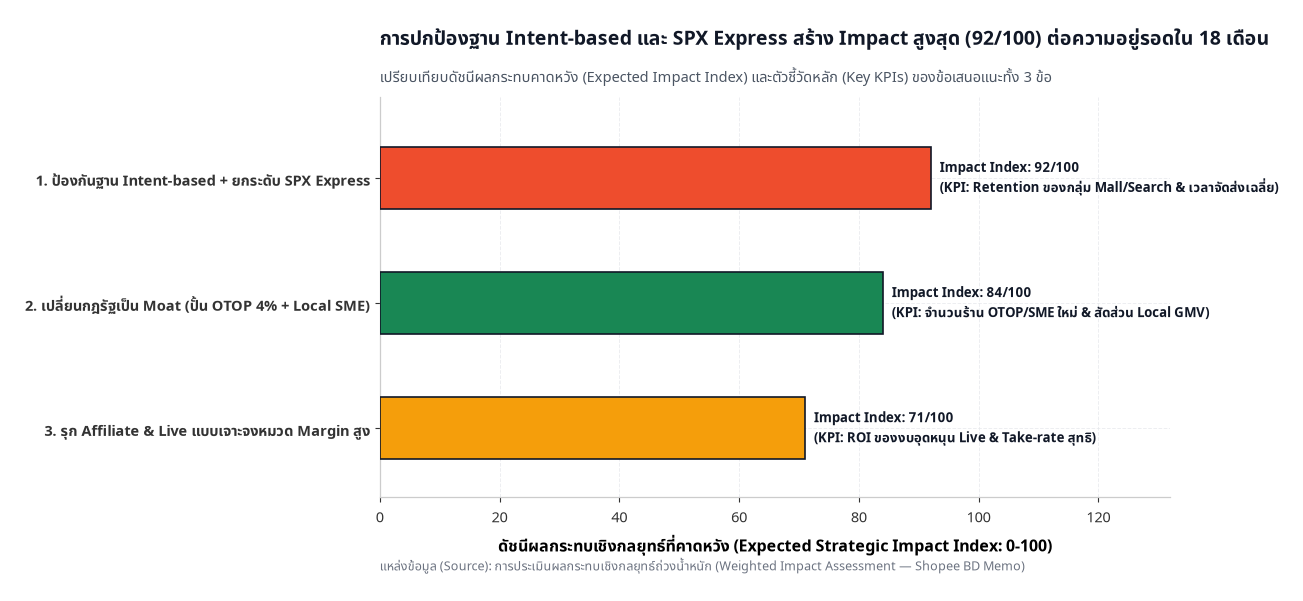

In [3]:
fig, ax = plt.subplots(figsize=(10.2, 5.2))

df_imp = rec_df.sort_values("expected_impact_index", ascending=True).reset_index(drop=True)
y_pos = np.arange(len(df_imp))
colors = ["#F59E0B", COLORS["OTOP"], COLORS["Shopee"]]

bars = ax.barh(y_pos, df_imp["expected_impact_index"], height=0.5, color=colors, edgecolor="#111827", linewidth=1.2, zorder=3)

for i, b in enumerate(bars):
    w = b.get_width()
    kpi = df_imp.loc[i, "key_kpi"]
    ax.text(w + 1.5, b.get_y() + b.get_height()/2, f"Impact Index: {w}/100\n(KPI: {kpi})",
            ha="left", va="center", fontsize=9.5, fontweight="bold", color="#111827")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_imp["rec_title"], fontsize=10.5, fontweight="bold")
ax.set_xlabel("ดัชนีผลกระทบเชิงกลยุทธ์ที่คาดหวัง (Expected Strategic Impact Index: 0-100)", fontweight="bold")
ax.set_xlim(0, 132)
ax.set_ylim(-0.55, 2.65)

chart_style.add_title_and_source(
    ax,
    title="การปกป้องฐาน Intent-based และ SPX Express สร้าง Impact สูงสุด (92/100) ต่อความอยู่รอดใน 18 เดือน",
    subtitle="เปรียบเทียบดัชนีผลกระทบคาดหวัง (Expected Impact Index) และตัวชี้วัดหลัก (Key KPIs) ของข้อเสนอแนะทั้ง 3 ข้อ",
    source_text="การประเมินผลกระทบเชิงกลยุทธ์ถ่วงน้ำหนัก (Weighted Impact Assessment — Shopee BD Memo)"
)

plt.savefig("../charts/06_2_expected_impact_summary.png")
plt.show()

> **Insight ของ Section 6:** *"คำตอบของ Shopee ในอีก 18 เดือนไม่ใช่การเผาเงินแลก GMV ทุกสมรภูมิ แต่คือการจัดสรรทรัพยากรแบบ 50 : 30 : 20 — 50% ปกป้องฐาน Intent & SPX Express, 30% เปลี่ยนกฎรัฐเป็น OTOP/Local Moat, และ 20% เจาะ Selective Affiliate เฉพาะหมวดกำไรสูง"*